# Simulación Estocástica de Tráfico Vehicular mediante un Modelo Oculto de Markov (HMM)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Trafico-Markov/blob/main/Simulacion_Markov_Trafico_Colab.ipynb)

---
### Institución Universitaria Digital de Antioquia (IU Digital)
- **Facultad:** Facultad de Ingeniería — Ingeniería de Software y Datos  
- **Asignatura:** Simulación — `PREICA2602B020045` (Módulo 2 — Actividad Didáctica 2)  
- **Docente:** Julian Andres Loaiza Lopez  
- **Grupo:** 25 | **Sede:** Medellín, Antioquia | **Fecha:** Noviembre de 2026  

#### Integrantes del Equipo:
1. **Adriana Andrea Agudelo Agudelo**
2. **Camilo Alberto Palacios Turriago**
3. **Juan Daniel Pulgarin García**
4. **Ruben Dario Jaramillo Cervantes**

---

## 1. Formulación Matemática y Pertinencia del Modelo Oculto de Markov (HMM)

En un corredor arterial urbano (p. ej., Autopista Norte / Avenida Regional en Medellín), el **régimen macroscópico real del flujo vehicular** es una variable física espacialmente distribuida que **no es directamente observable** en su totalidad por un sensor puntual. Formalizamos el fenómeno mediante la quíntupla canónica $\lambda = (\mathcal{S}, \mathcal{V}, \boldsymbol{\pi}, A, B)$:

1. **Espacio de Estados Ocultos ($\mathcal{S}$):** Condición operativa latente de la arteria en intervalos discretos de $\Delta t = 15\text{ min}$:
   $$\mathcal{S} = \{S_1:\text{Fluido},\; S_2:\text{Moderado},\; S_3:\text{Congestionado}\}$$
2. **Espacio de Observaciones Visibles ($\mathcal{V}$):** Lecturas telemétricas discretizadas de radares Doppler / espiras inductivas sujetas a ruido instrumental y varianza local:
   $$\mathcal{V} = \{V_1:\text{Velocidad Alta }(v > 60\text{ km/h}),\; V_2:\text{Velocidad Media }(30\text{–}60\text{ km/h}),\; V_3:\text{Velocidad Baja }(v < 30\text{ km/h})\}$$
3. **Propiedad Markoviana de Primer Orden e Independencia Condicional de Emisión:**
   $$P(X_{t+1} = s_j \mid X_t = s_i, X_{t-1}, \dots, X_0) = P(X_{t+1} = s_j \mid X_t = s_i) = a_{ij}, \qquad P(Y_t = v_k \mid X_t = s_j) = b_{jk}$$

Este cuaderno implementa desde cero el motor estocástico completo: validación axiomática de Kolmogorov, simulación Monte Carlo, decodificación global óptima por **Algoritmo de Viterbi** en escala logarítmica, suavizado bayesiano **Forward-Backward** ($\gamma_t$), distribución estacionaria exacta $\boldsymbol{\pi}^*$ y análisis de resiliencia ante perturbaciones viales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = ":"
plt.rcParams["grid.alpha"] = 0.6

print("[OK] Entorno científico cargado correctamente (NumPy, Pandas, Matplotlib).")

[OK] Entorno científico cargado correctamente (NumPy, Pandas, Matplotlib).


---
## 2. Implementación Completa de la Clase `TrafficHMM`

Implementamos la clase `TrafficHMM` de forma totalmente auto-contenida para ejecución directa en Google Colab, incluyendo:
- Validación de matrices estocásticas ($\sum_i \pi_i = 1$, $\sum_j a_{ij} = 1$, $\sum_k b_{jk} = 1$).
- Clasificador base sin memoria (`naive_sensor_decode`) para cuantificar la mejora aportada por el HMM.
- **Algoritmo de Viterbi** en log-espacio ($\mathcal{O}(T \cdot N^2)$) libre de *underflow* numérico.
- **Algoritmo Forward-Backward** escalado para calcular probabilidades marginales a posteriori $\gamma_t(i) = P(X_t = s_i \mid Y_{1:T}, \lambda)$.
- Solución algebraica exacta de la **distribución estacionaria** $\boldsymbol{\pi}^* A = \boldsymbol{\pi}^*$, **tiempos de permanencia** $\mathbb{E}[T_i] = \frac{1}{1 - a_{ii}}$ y **tiempos medios de retorno de Kac** $\mu_i = \frac{1}{\pi^*_i}$.

In [2]:
class TrafficHMM:
    """Modelo Oculto de Markov (HMM) de tiempo discreto para tráfico vehicular urbano."""

    def __init__(self, states=None, observations=None, initial_probs=None, transition_matrix=None, emission_matrix=None):
        self.states = states or ["Fluido", "Moderado", "Congestionado"]
        self.observations = observations or ["Velocidad Alta", "Velocidad Media", "Velocidad Baja"]
        self.N = len(self.states)
        self.M = len(self.observations)

        self.state_to_idx = {s: i for i, s in enumerate(self.states)}
        self.idx_to_state = {i: s for i, s in enumerate(self.states)}
        self.obs_to_idx = {o: i for i, o in enumerate(self.observations)}
        self.idx_to_obs = {i: o for i, o in enumerate(self.observations)}

        # Vector inicial pi (inicio de jornada 06:00 AM)
        self.pi = np.array(initial_probs if initial_probs is not None else [0.70, 0.20, 0.10], dtype=float)

        # Matriz de Transición de Estados Ocultos A (3x3)
        self.A = np.array(transition_matrix if transition_matrix is not None else [
            [0.70, 0.25, 0.05],  # Desde Fluido
            [0.20, 0.60, 0.20],  # Desde Moderado
            [0.05, 0.30, 0.65],  # Desde Congestionado
        ], dtype=float)

        # Matriz de Emisión de Sensores B (3x3)
        self.B = np.array(emission_matrix if emission_matrix is not None else [
            [0.80, 0.15, 0.05],  # Estado real Fluido
            [0.20, 0.65, 0.15],  # Estado real Moderado
            [0.05, 0.20, 0.75],  # Estado real Congestionado
        ], dtype=float)

        self._validate_matrices()

    def _validate_matrices(self):
        if np.any(self.pi < 0) or not np.isclose(np.sum(self.pi), 1.0, atol=1e-4):
            raise ValueError("El vector inicial pi debe ser no negativo y sumar 1.0")
        if self.A.shape != (self.N, self.N) or np.any(self.A < 0) or not np.allclose(np.sum(self.A, axis=1), 1.0, atol=1e-4):
            raise ValueError("Cada fila de la matriz A debe ser no negativa y sumar 1.0")
        if self.B.shape != (self.N, self.M) or np.any(self.B < 0) or not np.allclose(np.sum(self.B, axis=1), 1.0, atol=1e-4):
            raise ValueError("Cada fila de la matriz B debe ser no negativa y sumar 1.0")

    def simulate(self, T, seed=None):
        """Genera una secuencia sintética de longitud T mediante muestreo Monte Carlo."""
        rng = np.random.default_rng(seed)
        states = np.zeros(T, dtype=int)
        obs = np.zeros(T, dtype=int)
        states[0] = rng.choice(self.N, p=self.pi)
        obs[0] = rng.choice(self.M, p=self.B[states[0]])
        for t in range(1, T):
            states[t] = rng.choice(self.N, p=self.A[states[t - 1]])
            obs[t] = rng.choice(self.M, p=self.B[states[t]])
        return states.tolist(), obs.tolist()

    def naive_sensor_decode(self, obs_seq):
        """Clasificador puntual sin memoria markoviana: argmax_i B[i, Y_t]."""
        return [int(np.argmax(self.B[:, o])) for o in obs_seq]

    def viterbi(self, obs_seq):
        """Algoritmo de Viterbi en log-espacio para hallar X* = argmax_X P(X, Y | lambda)."""
        T = len(obs_seq)
        eps = 1e-12
        log_pi = np.log(np.maximum(self.pi, eps))
        log_A = np.log(np.maximum(self.A, eps))
        log_B = np.log(np.maximum(self.B, eps))

        V = np.zeros((T, self.N))
        backpointer = np.zeros((T, self.N), dtype=int)
        V[0, :] = log_pi + log_B[:, obs_seq[0]]

        for t in range(1, T):
            o = obs_seq[t]
            for j in range(self.N):
                probs = V[t - 1, :] + log_A[:, j]
                best_prev = int(np.argmax(probs))
                V[t, j] = probs[best_prev] + log_B[j, o]
                backpointer[t, j] = best_prev

        best_last = int(np.argmax(V[T - 1, :]))
        best_path = [0] * T
        best_path[T - 1] = best_last
        for t in range(T - 2, -1, -1):
            best_path[t] = int(backpointer[t + 1, best_path[t + 1]])
        return best_path, float(V[T - 1, best_last])

    def forward_backward(self, obs_seq):
        """Suavizado Bayesiano Forward-Backward: calcula gamma_t(i) = P(X_t = s_i | Y_{1:T})."""
        T = len(obs_seq)
        alpha = np.zeros((T, self.N))
        scales = np.zeros(T)

        alpha[0, :] = self.pi * self.B[:, obs_seq[0]]
        scales[0] = max(float(np.sum(alpha[0, :])), 1e-15)
        alpha[0, :] /= scales[0]

        for t in range(1, T):
            alpha[t, :] = (alpha[t - 1, :] @ self.A) * self.B[:, obs_seq[t]]
            scales[t] = max(float(np.sum(alpha[t, :])), 1e-15)
            alpha[t, :] /= scales[t]

        beta = np.zeros((T, self.N))
        beta[T - 1, :] = 1.0
        for t in range(T - 2, -1, -1):
            beta[t, :] = (self.A @ (self.B[:, obs_seq[t + 1]] * beta[t + 1, :])) / scales[t + 1]

        gamma = alpha * beta
        gamma /= np.maximum(np.sum(gamma, axis=1, keepdims=True), 1e-15)
        posterior_states = np.argmax(gamma, axis=1).tolist()
        log_likelihood = float(np.sum(np.log(scales)))
        return gamma, posterior_states, log_likelihood

    def compute_stationary_distribution(self):
        """Resuelve exactamente (A^T - I) pi*^T = 0 sujeto a sum(pi*) = 1."""
        Q = self.A.T - np.eye(self.N)
        Q[-1, :] = 1.0
        b = np.zeros(self.N)
        b[-1] = 1.0
        pi_star = np.linalg.solve(Q, b)
        return pi_star / np.sum(pi_star)

    def expected_holding_times(self):
        """Tiempo esperado de permanencia continua E[T_i] = 1 / (1 - a_ii)."""
        return {s: 1.0 / (1.0 - self.A[i, i]) for i, s in enumerate(self.states)}

    def mean_recurrence_times(self):
        """Tiempo medio de retorno de Kac mu_i = 1 / pi*_i."""
        pi_star = self.compute_stationary_distribution()
        return {s: 1.0 / float(pi_star[i]) for i, s in enumerate(self.states)}


hmm = TrafficHMM()
print("[OK] Modelo TrafficHMM instanciado y validado estocásticamente.")

[OK] Modelo TrafficHMM instanciado y validado estocásticamente.


---
## 3. Arquitectura Gráfica del HMM y Propiedades Analíticas Estacionarias

Visualizamos primero el grafo dirigido bipartito que distingue explícitamente la **Capa Oculta** ($X_t$: cadena de Markov con transiciones $a_{ij}$) de la **Capa Observable** ($Y_t$: emisiones sensoriales $b_{jk}$), seguido del cálculo analítico exacto del régimen estacionario.

<>:12: SyntaxWarning: invalid escape sequence '\i'
<>:14: SyntaxWarning: invalid escape sequence '\i'
<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\i'
<>:14: SyntaxWarning: invalid escape sequence '\i'
<>:26: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\944762245.py:12: SyntaxWarning: invalid escape sequence '\i'
  ax.text(0.7, 7.00, "CAPA OCULTA / LATENTE — Cadena de Markov Subyacente ($X_t \in \mathcal{S}$: Condición Vial Real)",
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\944762245.py:14: SyntaxWarning: invalid escape sequence '\i'
  ax.text(0.7, 0.52, "CAPA OBSERVABLE / VISIBLE — Telemetría ($Y_t \in \mathcal{V}$)",
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\944762245.py:26: SyntaxWarning: invalid escape sequence '\p'
  ax.text(x, y_hidden - 0.42, f"$\pi_{i+1}={hmm.pi[i]:.2f}$", ha="center", va="center", color="white", fontsize=8.5, fontwe

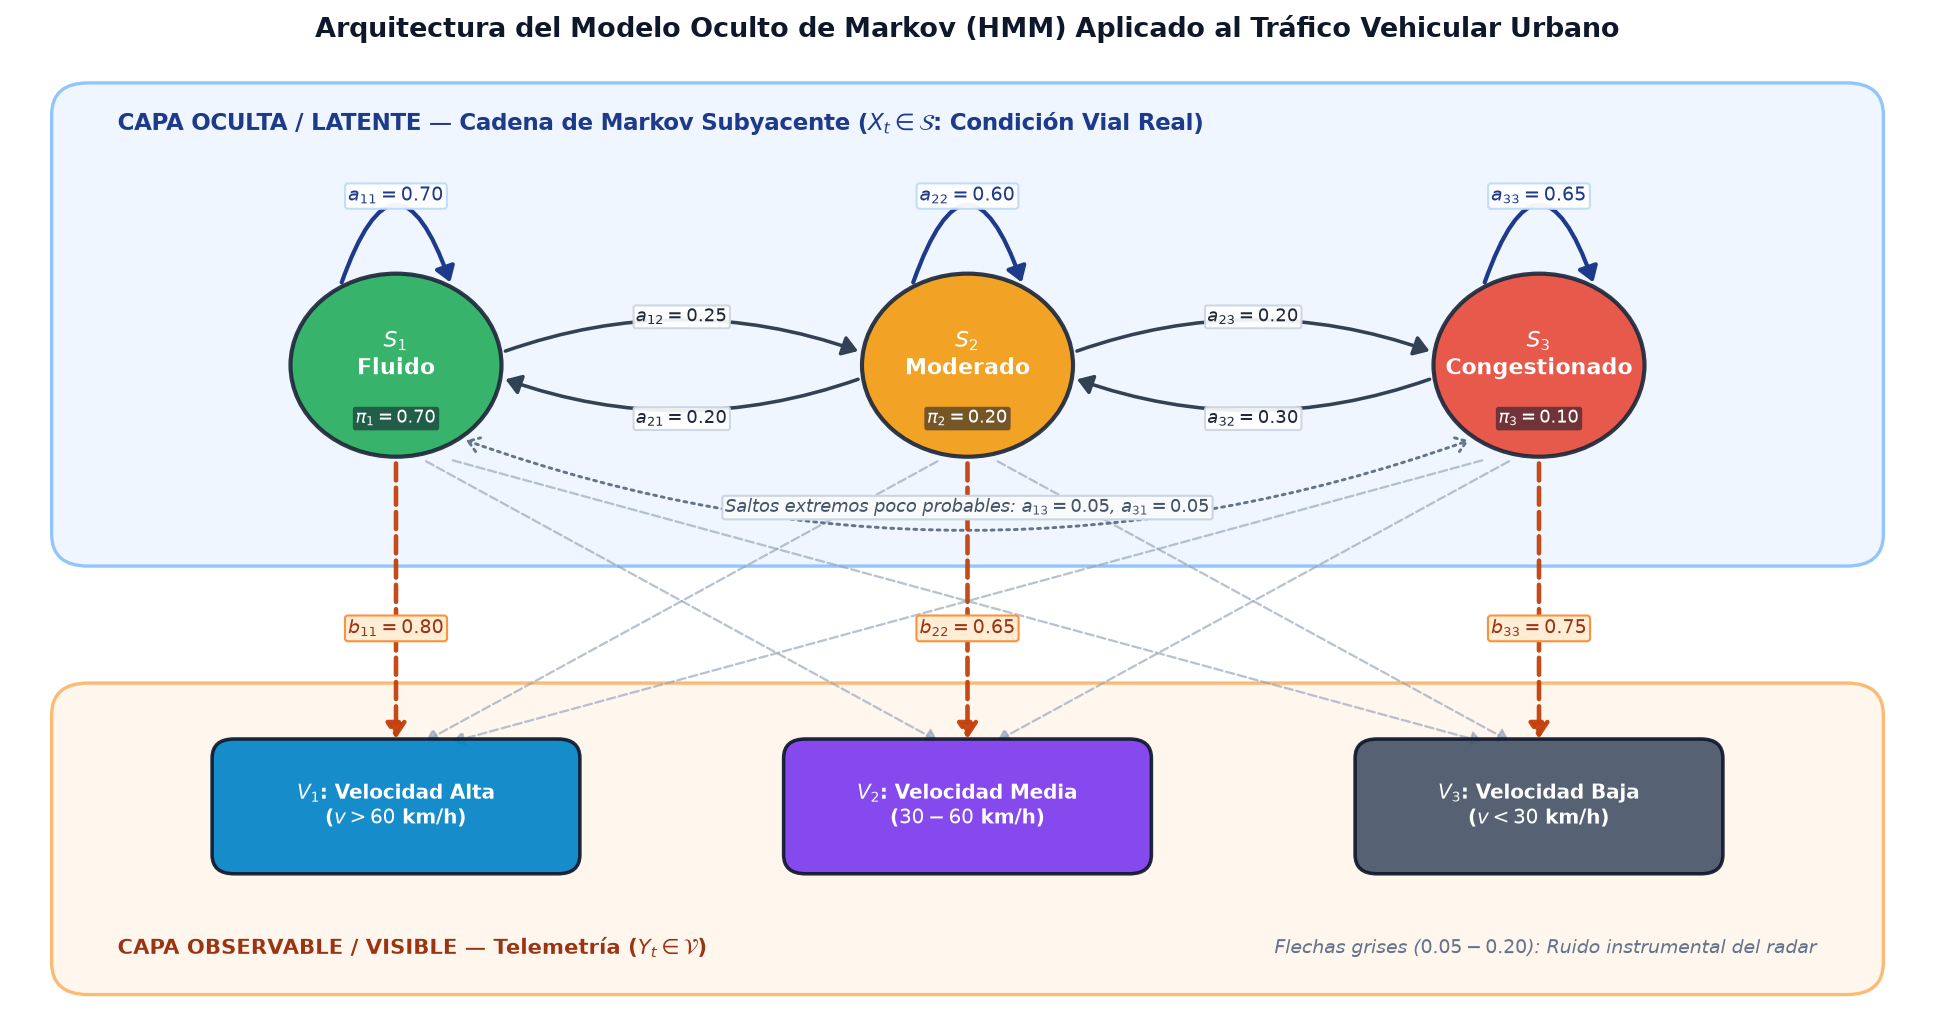

In [3]:
# Figura 0: Grafo Dirigido de la Arquitectura del HMM
fig, ax = plt.subplots(figsize=(13, 7.0), dpi=150)
ax.set_xlim(0, 13)
ax.set_ylim(0, 7.6)
ax.axis("off")

ax.add_patch(FancyBboxPatch((0.4, 3.72), 12.2, 3.50, boxstyle="round,pad=0.15,rounding_size=0.25",
                            facecolor="#EFF6FF", edgecolor="#93C5FD", linewidth=1.6, zorder=0))
ax.add_patch(FancyBboxPatch((0.4, 0.35), 12.2, 2.15, boxstyle="round,pad=0.15,rounding_size=0.25",
                            facecolor="#FFF7ED", edgecolor="#FDBA74", linewidth=1.6, zorder=0))

ax.text(0.7, 7.00, "CAPA OCULTA / LATENTE — Cadena de Markov Subyacente ($X_t \in \mathcal{S}$: Condición Vial Real)",
        fontsize=10.8, fontweight="bold", color="#1E3A8A")
ax.text(0.7, 0.52, "CAPA OBSERVABLE / VISIBLE — Telemetría ($Y_t \in \mathcal{V}$)",
        fontsize=10.2, fontweight="bold", color="#9A3412")
ax.text(12.3, 0.52, "Flechas grises ($0.05 - 0.20$): Ruido instrumental del radar",
        ha="right", fontsize=9.0, color="#64748B", style="italic")

xs, y_hidden, y_obs, r_node = [2.6, 6.5, 10.4], 5.15, 1.68, 0.72
state_colors = ["#27ae60", "#f39c12", "#e74c3c"]
obs_labels = ["Velocidad Alta\n($v > 60$ km/h)", "Velocidad Media\n($30 - 60$ km/h)", "Velocidad Baja\n($v < 30$ km/h)"]

for i, (x, st_name, col) in enumerate(zip(xs, hmm.states, state_colors)):
    ax.add_patch(Circle((x, y_hidden), r_node, facecolor=col, edgecolor="#1E293B", linewidth=2.0, alpha=0.92, zorder=4))
    ax.text(x, y_hidden + 0.08, f"$S_{i+1}$\n{st_name}", ha="center", va="center", color="white", fontsize=10.5, fontweight="bold", zorder=5)
    ax.text(x, y_hidden - 0.42, f"$\pi_{i+1}={hmm.pi[i]:.2f}$", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.15", facecolor="#0F172A", edgecolor="none", alpha=0.55), zorder=5)
    ax.add_patch(FancyArrowPatch((x - 0.38, y_hidden + 0.62), (x + 0.38, y_hidden + 0.62),
                                 connectionstyle="arc3,rad=-1.45", arrowstyle="-|>,head_length=6,head_width=4",
                                 color="#1E3A8A", linewidth=2.0, zorder=3))
    ax.text(x, y_hidden + 1.33, f"$a_{{{i+1}{i+1}}}={hmm.A[i, i]:.2f}$", ha="center", va="center",
            fontsize=9.2, fontweight="bold", color="#1E3A8A",
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="#BFDBFE", alpha=0.95), zorder=6)

for i, j, dy in [(0, 1, 0.20), (1, 0, -0.20), (1, 2, 0.20), (2, 1, -0.20)]:
    x_s = xs[i] + (r_node if j > i else -r_node)
    x_e = xs[j] - (r_node if j > i else -r_node)
    ax.add_patch(FancyArrowPatch((x_s, y_hidden + dy * 0.5), (x_e, y_hidden + dy * 0.5),
                                 connectionstyle="arc3,rad=-0.18", arrowstyle="-|>,head_length=6,head_width=4",
                                 color="#334155", linewidth=1.7, zorder=3))
    ax.text(0.5 * (xs[i] + xs[j]), y_hidden + (0.38 if j > i else -0.42), f"$a_{{{i+1}{j+1}}}={hmm.A[i, j]:.2f}$",
            ha="center", va="center", fontsize=8.8, fontweight="bold", color="#1E293B",
            bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="#CBD5E1", alpha=0.92), zorder=6)

ax.add_patch(FancyArrowPatch((xs[0] + 0.45, y_hidden - 0.58), (xs[2] - 0.45, y_hidden - 0.58),
                             connectionstyle="arc3,rad=0.18", arrowstyle="<->,head_length=5,head_width=3.5",
                             color="#64748B", linestyle=":", linewidth=1.4, zorder=2))
ax.text(6.5, y_hidden - 1.12, f"Saltos extremos poco probables: $a_{{13}}={hmm.A[0,2]:.2f}$, $a_{{31}}={hmm.A[2,0]:.2f}$",
        ha="center", va="center", fontsize=8.5, color="#475569", style="italic",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="#F8FAFC", edgecolor="#CBD5E1"), zorder=6)

for k, (x, lbl, ocol) in enumerate(zip(xs, obs_labels, ["#0284C7", "#7C3AED", "#475569"])):
    ax.add_patch(FancyBboxPatch((x - 2.35 / 2, y_obs - 0.45), 2.35, 0.90, boxstyle="round,pad=0.08,rounding_size=0.15",
                                facecolor=ocol, edgecolor="#0F172A", linewidth=1.7, alpha=0.92, zorder=4))
    ax.text(x, y_obs, f"$V_{k+1}$: {lbl}", ha="center", va="center", color="white", fontsize=9.5, fontweight="bold", zorder=5)

for j in range(3):
    for k in range(3):
        is_diag = (j == k)
        ax.add_patch(FancyArrowPatch((xs[j] + (k - j) * 0.18, y_hidden - r_node - 0.02),
                                     (xs[k] + (j - k) * 0.18, y_obs + 0.50),
                                     arrowstyle="-|>,head_length=6,head_width=4" if is_diag else "-|>,head_length=4.5,head_width=3",
                                     color="#C2410C" if is_diag else "#94A3B8", linestyle="--",
                                     linewidth=2.2 if is_diag else 1.1, alpha=0.95 if is_diag else 0.65,
                                     zorder=3 if is_diag else 1))
        if is_diag:
            ax.text(xs[j], 3.08, f"$b_{{{j+1}{k+1}}}={hmm.B[j, k]:.2f}$", ha="center", va="center",
                    fontsize=9.2, fontweight="bold", color="#9A3412",
                    bbox=dict(boxstyle="round,pad=0.16", facecolor="#FFEDD5", edgecolor="#FB923C"), zorder=6)

ax.set_title("Arquitectura del Modelo Oculto de Markov (HMM) Aplicado al Tráfico Vehicular Urbano",
             fontsize=13, fontweight="bold", color="#0F172A", pad=8)
plt.tight_layout()
plt.show()

In [4]:
# Tablas de Parámetros y Propiedades Estacionarias Analíticas
df_A = pd.DataFrame(hmm.A, index=[f"Desde {s}" for s in hmm.states], columns=[f"Hacia {s}" for s in hmm.states])
df_B = pd.DataFrame(hmm.B, index=[f"Real: {s}" for s in hmm.states], columns=hmm.observations)

print("=== MATRIZ DE TRANSICIÓN DE ESTADOS OCULTOS (A) ===")
display(df_A)

print("\n=== MATRIZ DE EMISIÓN DE SENSORES (B) ===")
display(df_B)

pi_star = hmm.compute_stationary_distribution()
holding = hmm.expected_holding_times()
recurrence = hmm.mean_recurrence_times()

df_props = pd.DataFrame({
    "Estado Oculto": hmm.states,
    "Prob. Inicial pi_0": [f"{p*100:.1f}%" for p in hmm.pi],
    "Dist. Estacionaria pi*": [f"{p*100:.2f}% ({p:.4f})" for p in pi_star],
    "Permanencia Media (Pasos)": [round(holding[s], 2) for s in hmm.states],
    "Permanencia Media (Min)": [round(holding[s] * 15, 1) for s in hmm.states],
    "Retorno de Kac (Min)": [round(recurrence[s] * 15, 1) for s in hmm.states],
})
print("\n=== PROPIEDADES ANALÍTICAS EN RÉGIMEN ESTACIONARIO ===")
display(df_props)

=== MATRIZ DE TRANSICIÓN DE ESTADOS OCULTOS (A) ===


,Hacia Fluido,Hacia Moderado,Hacia Congestionado
Desde Fluido,0.70,0.25,0.05
Desde Moderado,0.20,0.60,0.20
Desde Congestionado,0.05,0.30,0.65



=== MATRIZ DE EMISIÓN DE SENSORES (B) ===


,Velocidad Alta,Velocidad Media,Velocidad Baja
Real: Fluido,0.80,0.15,0.05
Real: Moderado,0.20,0.65,0.15
Real: Congestionado,0.05,0.20,0.75



=== PROPIEDADES ANALÍTICAS EN RÉGIMEN ESTACIONARIO ===


,Estado Oculto,Prob. Inicial pi_0,Dist. Estacionaria pi*,Permanencia Media (Pasos),Permanencia Media (Min),Retorno de Kac (Min)
0,Fluido,70.0%,31.68% (0.3168),3.33,50.0,47.3
1,Moderado,20.0%,40.59% (0.4059),2.50,37.5,37.0
2,Congestionado,10.0%,27.72% (0.2772),2.86,42.9,54.1


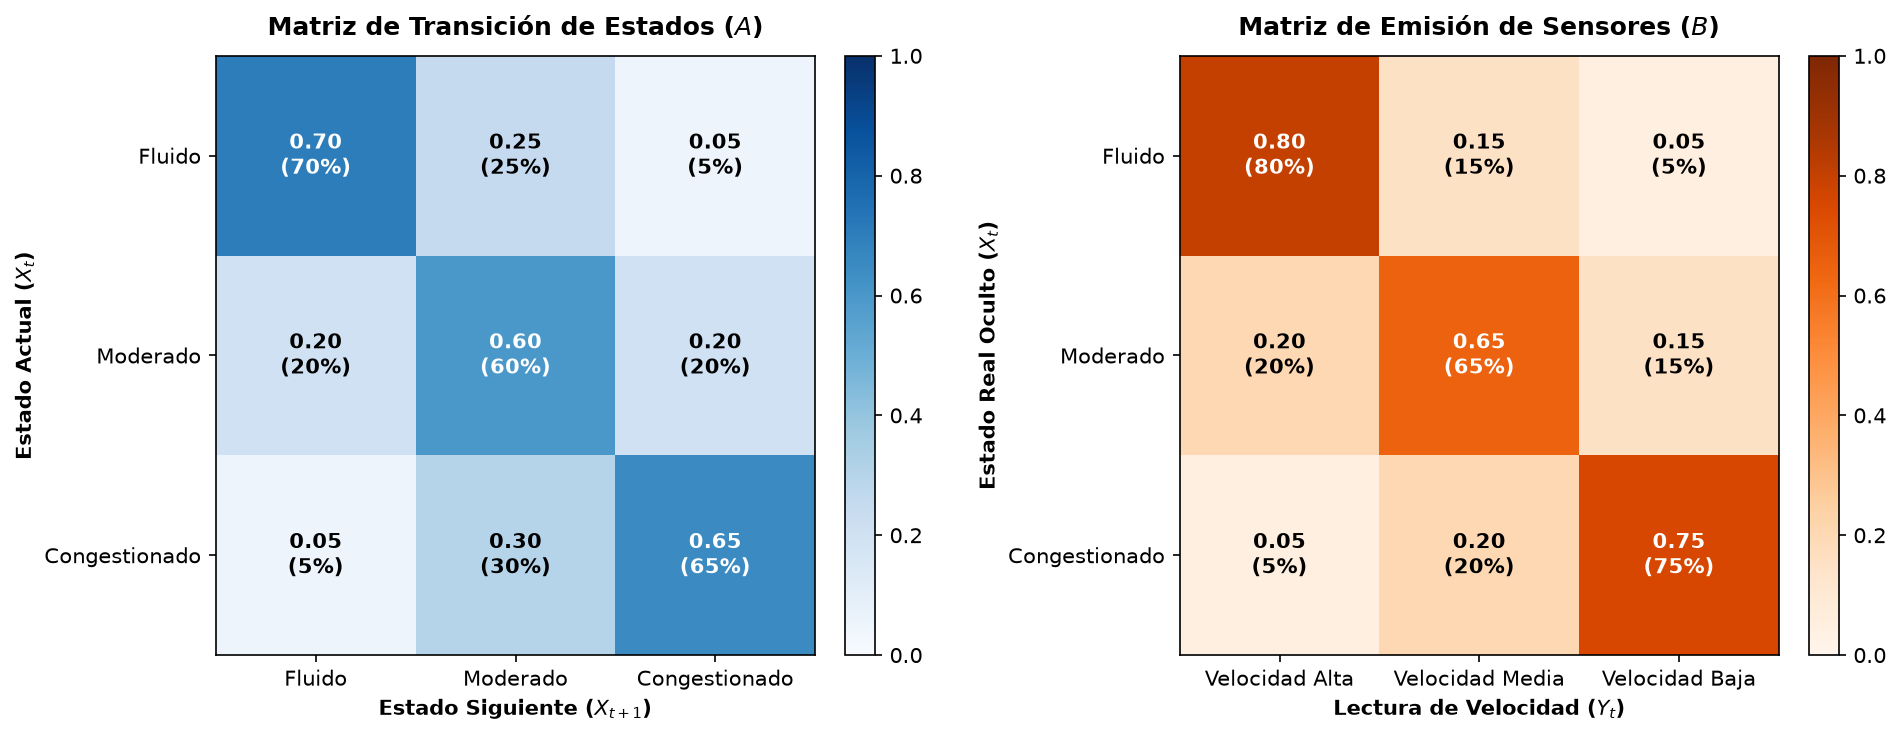

In [5]:
# Figura 1: Mapas de Calor de las Matrices Estocásticas A y B
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

im1 = ax1.imshow(hmm.A, cmap="Blues", vmin=0, vmax=1)
ax1.set_title("Matriz de Transición de Estados ($A$)", fontsize=12, fontweight="bold", pad=10)
ax1.set_xticks(range(3)); ax1.set_yticks(range(3))
ax1.set_xticklabels(hmm.states); ax1.set_yticklabels(hmm.states)
ax1.set_xlabel("Estado Siguiente ($X_{t+1}$)", fontweight="bold")
ax1.set_ylabel("Estado Actual ($X_t$)", fontweight="bold")
ax1.grid(False)
for i in range(3):
    for j in range(3):
        val = hmm.A[i, j]
        ax1.text(j, i, f"{val:.2f}\n({val*100:.0f}%)", ha="center", va="center",
                 color="white" if val > 0.5 else "black", fontweight="bold")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

im2 = ax2.imshow(hmm.B, cmap="Oranges", vmin=0, vmax=1)
ax2.set_title("Matriz de Emisión de Sensores ($B$)", fontsize=12, fontweight="bold", pad=10)
ax2.set_xticks(range(3)); ax2.set_yticks(range(3))
ax2.set_xticklabels(hmm.observations); ax2.set_yticklabels(hmm.states)
ax2.set_xlabel("Lectura de Velocidad ($Y_t$)", fontweight="bold")
ax2.set_ylabel("Estado Real Oculto ($X_t$)", fontweight="bold")
ax2.grid(False)
for i in range(3):
    for j in range(3):
        val = hmm.B[i, j]
        ax2.text(j, i, f"{val:.2f}\n({val*100:.0f}%)", ha="center", va="center",
                 color="white" if val > 0.5 else "black", fontweight="bold")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:7: SyntaxWarning: invalid escape sequence '\p'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\p'
<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:7: SyntaxWarning: invalid escape sequence '\p'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\2684273698.py:6: SyntaxWarning: invalid escape sequence '\p'
  ("Inicio 100% Fluido ($\pi_0 = [1, 0, 0]$)", np.array([1.0, 0.0, 0.0])),
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\2684273698.py:7: SyntaxWarning: invalid escape sequence '\p'
  ("Inicio 100% Congestionado ($\pi_0 = [0, 0, 1]$)", np.array([0.0, 0.0, 1.0])),
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\2684273698.py:13: SyntaxWarning: invalid escape sequence '\m'
  axes[ax_idx].plot(range(steps + 1), history[:, s_idx], label=f"$P(X_k = \

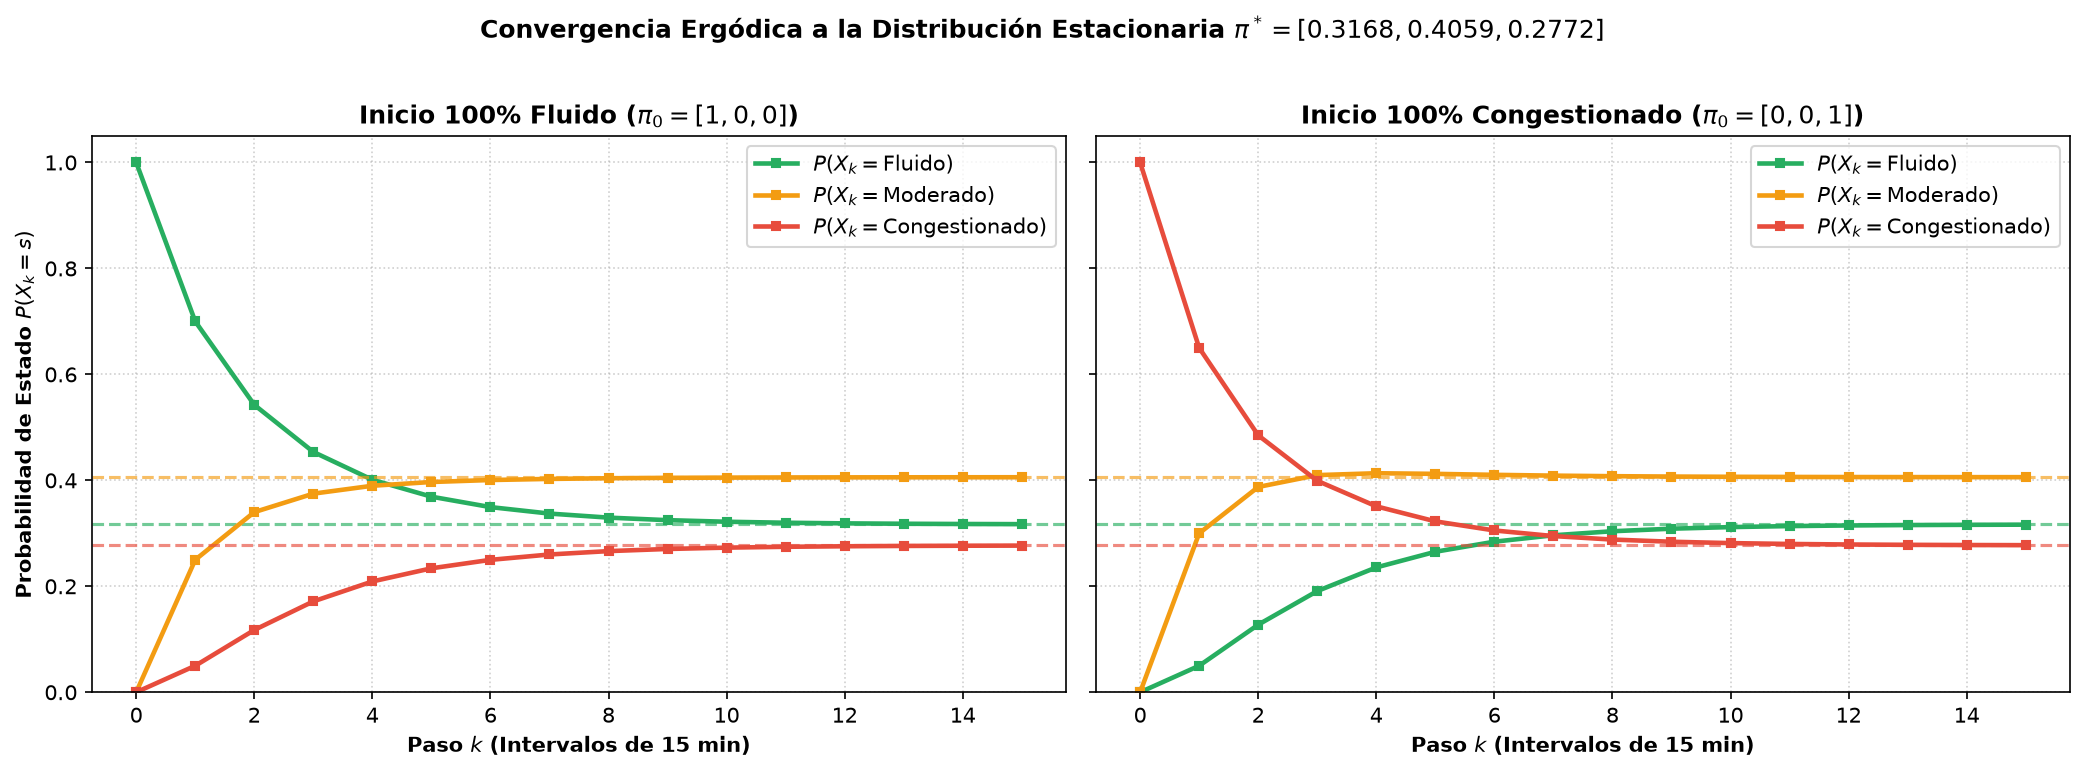

In [6]:
# Figura 2: Convergencia Ergódica a la Distribución Estacionaria pi* (Chapman-Kolmogorov)
steps = 15
colors = {"Fluido": "#27ae60", "Moderado": "#f39c12", "Congestionado": "#e74c3c"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150, sharey=True)
scenarios = [
    ("Inicio 100% Fluido ($\pi_0 = [1, 0, 0]$)", np.array([1.0, 0.0, 0.0])),
    ("Inicio 100% Congestionado ($\pi_0 = [0, 0, 1]$)", np.array([0.0, 0.0, 1.0])),
]

for ax_idx, (title, pi_init) in enumerate(scenarios):
    history = np.array([pi_init @ np.linalg.matrix_power(hmm.A, k) for k in range(steps + 1)])
    for s_idx, state in enumerate(hmm.states):
        axes[ax_idx].plot(range(steps + 1), history[:, s_idx], label=f"$P(X_k = \mathrm{{{state}}})$",
                          color=colors[state], linewidth=2.2, marker="s", markersize=4)
        axes[ax_idx].axhline(pi_star[s_idx], color=colors[state], linestyle="--", alpha=0.65)
    axes[ax_idx].set_title(title, fontweight="bold")
    axes[ax_idx].set_xlabel("Paso $k$ (Intervalos de 15 min)", fontweight="bold")
    if ax_idx == 0:
        axes[ax_idx].set_ylabel("Probabilidad de Estado $P(X_k = s)$", fontweight="bold")
    axes[ax_idx].set_ylim(0, 1.05)
    axes[ax_idx].legend(loc="upper right")

fig.suptitle(f"Convergencia Ergódica a la Distribución Estacionaria $\pi^* = [{pi_star[0]:.4f}, {pi_star[1]:.4f}, {pi_star[2]:.4f}]$",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Simulación de una Jornada de 24 Horas (96 Intervalos) e Inferencia Bayesiana

Simulamos 96 intervalos consecutivos de 15 minutos (`06:00` a `05:45`, semilla `seed=42`). Comparamos:
1. **Sensor Crudo Sin Memoria** ($\hat{X}_t = \arg\max_i B_{i, Y_t}$), que oscila erráticamente ante cada lectura atípica del radar.
2. **Algoritmo de Viterbi** ($X^*_{1:T} = \arg\max_X P(X, Y \mid \lambda)$), que impone coherencia física markoviana y filtra el ruido sensorial.
3. **Suavizado Forward-Backward** ($\gamma_t(i) = P(X_t = s_i \mid Y_{1:T}, \lambda)$), que cuantifica la certidumbre probabilística minuto a minuto.

In [7]:
T = 96
real_states, observations = hmm.simulate(T=T, seed=42)
naive_states = hmm.naive_sensor_decode(observations)
viterbi_states, log_prob_vit = hmm.viterbi(observations)
gamma, posterior_states, log_lik = hmm.forward_backward(observations)

timestamps = [f"{(6*60 + s*15)//60 % 24:02d}:{(6*60 + s*15)%60:02d}" for s in range(T)]

df_sim = pd.DataFrame({
    "Paso": np.arange(T),
    "Hora": timestamps,
    "Estado_Real": [hmm.idx_to_state[s] for s in real_states],
    "Observacion_Sensor": [hmm.idx_to_obs[o] for o in observations],
    "Sensor_Crudo": [hmm.idx_to_state[s] for s in naive_states],
    "Inferencia_Viterbi": [hmm.idx_to_state[s] for s in viterbi_states],
    "Prob_Fluido": np.round(gamma[:, 0], 3),
    "Prob_Moderado": np.round(gamma[:, 1], 3),
    "Prob_Congestionado": np.round(gamma[:, 2], 3),
    "Acierto_Viterbi": np.array(real_states) == np.array(viterbi_states),
})

acc_vit = float(df_sim["Acierto_Viterbi"].mean())
switches_real = int(np.sum(np.diff(real_states) != 0))
switches_raw = int(np.sum(np.diff(naive_states) != 0))
switches_vit = int(np.sum(np.diff(viterbi_states) != 0))
jitter_reduction = (1.0 - switches_vit / switches_raw) * 100.0

print(f"• Exactitud Algoritmo de Viterbi: {acc_vit*100:.2f}% ({int(df_sim['Acierto_Viterbi'].sum())}/{T} intervalos)")
print(f"• Log-Verosimilitud Conjunta Viterbi log P(X*, Y): {log_prob_vit:.2f} | Marginal log P(Y): {log_lik:.2f}")
print(f"• Cambios de Estado en 24h -> Real: {switches_real} | Sensor Crudo: {switches_raw} | Viterbi: {switches_vit} (-{jitter_reduction:.1f}% ruido)")
print("\n=== MUESTRA DE LA SECUENCIA SIMULADA PASO A PASO (PRIMEROS 15 INTERVALOS: 06:00 - 09:30) ===")
display(df_sim.head(15))

• Exactitud Algoritmo de Viterbi: 73.96% (71/96 intervalos)
• Log-Verosimilitud Conjunta Viterbi log P(X*, Y): -121.24 | Marginal log P(Y): -96.29
• Cambios de Estado en 24h -> Real: 32 | Sensor Crudo: 53 | Viterbi: 21 (-60.4% ruido)

=== MUESTRA DE LA SECUENCIA SIMULADA PASO A PASO (PRIMEROS 15 INTERVALOS: 06:00 - 09:30) ===


,Paso,Hora,Estado_Real,Observacion_Sensor,Sensor_Crudo,Inferencia_Viterbi,Prob_Fluido,Prob_Moderado,Prob_Congestionado,Acierto_Viterbi
0,0,06:00,Moderado,Velocidad Media,Moderado,Moderado,0.162,0.603,0.235,True
1,1,06:15,Congestionado,Velocidad Baja,Congestionado,Congestionado,0.030,0.211,0.759,True
2,2,06:30,Moderado,Velocidad Baja,Congestionado,Congestionado,0.022,0.219,0.759,False
3,3,06:45,Moderado,Velocidad Media,Moderado,Moderado,0.073,0.745,0.181,True
4,4,07:00,Fluido,Velocidad Alta,Fluido,Moderado,0.426,0.518,0.056,False
5,5,07:15,Fluido,Velocidad Media,Moderado,Moderado,0.185,0.765,0.049,False
6,6,07:30,Fluido,Velocidad Media,Moderado,Moderado,0.236,0.730,0.034,False
7,7,07:45,Fluido,Velocidad Alta,Fluido,Fluido,0.730,0.256,0.014,True
8,8,08:00,Fluido,Velocidad Alta,Fluido,Fluido,0.719,0.265,0.016,True
9,9,08:15,Moderado,Velocidad Media,Moderado,Moderado,0.172,0.771,0.057,True


<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\g'
<>:27: SyntaxWarning: invalid escape sequence '\g'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\g'
<>:27: SyntaxWarning: invalid escape sequence '\g'
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\125956427.py:23: SyntaxWarning: invalid escape sequence '\m'
  labels=["$P(\mathrm{Fluido} \mid Y)$", "$P(\mathrm{Moderado} \mid Y)$", "$P(\mathrm{Congestionado} \mid Y)$"],
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\125956427.py:23: SyntaxWarning: invalid escape sequence '\m'
  labels=["$P(\mathrm{Fluido} \mid Y)$", "$P(\mathrm{Moderado} \mid Y)$", "$P(\mathrm{Congestionado} \mid Y)$"],
C:\Users\Camilo Palaci

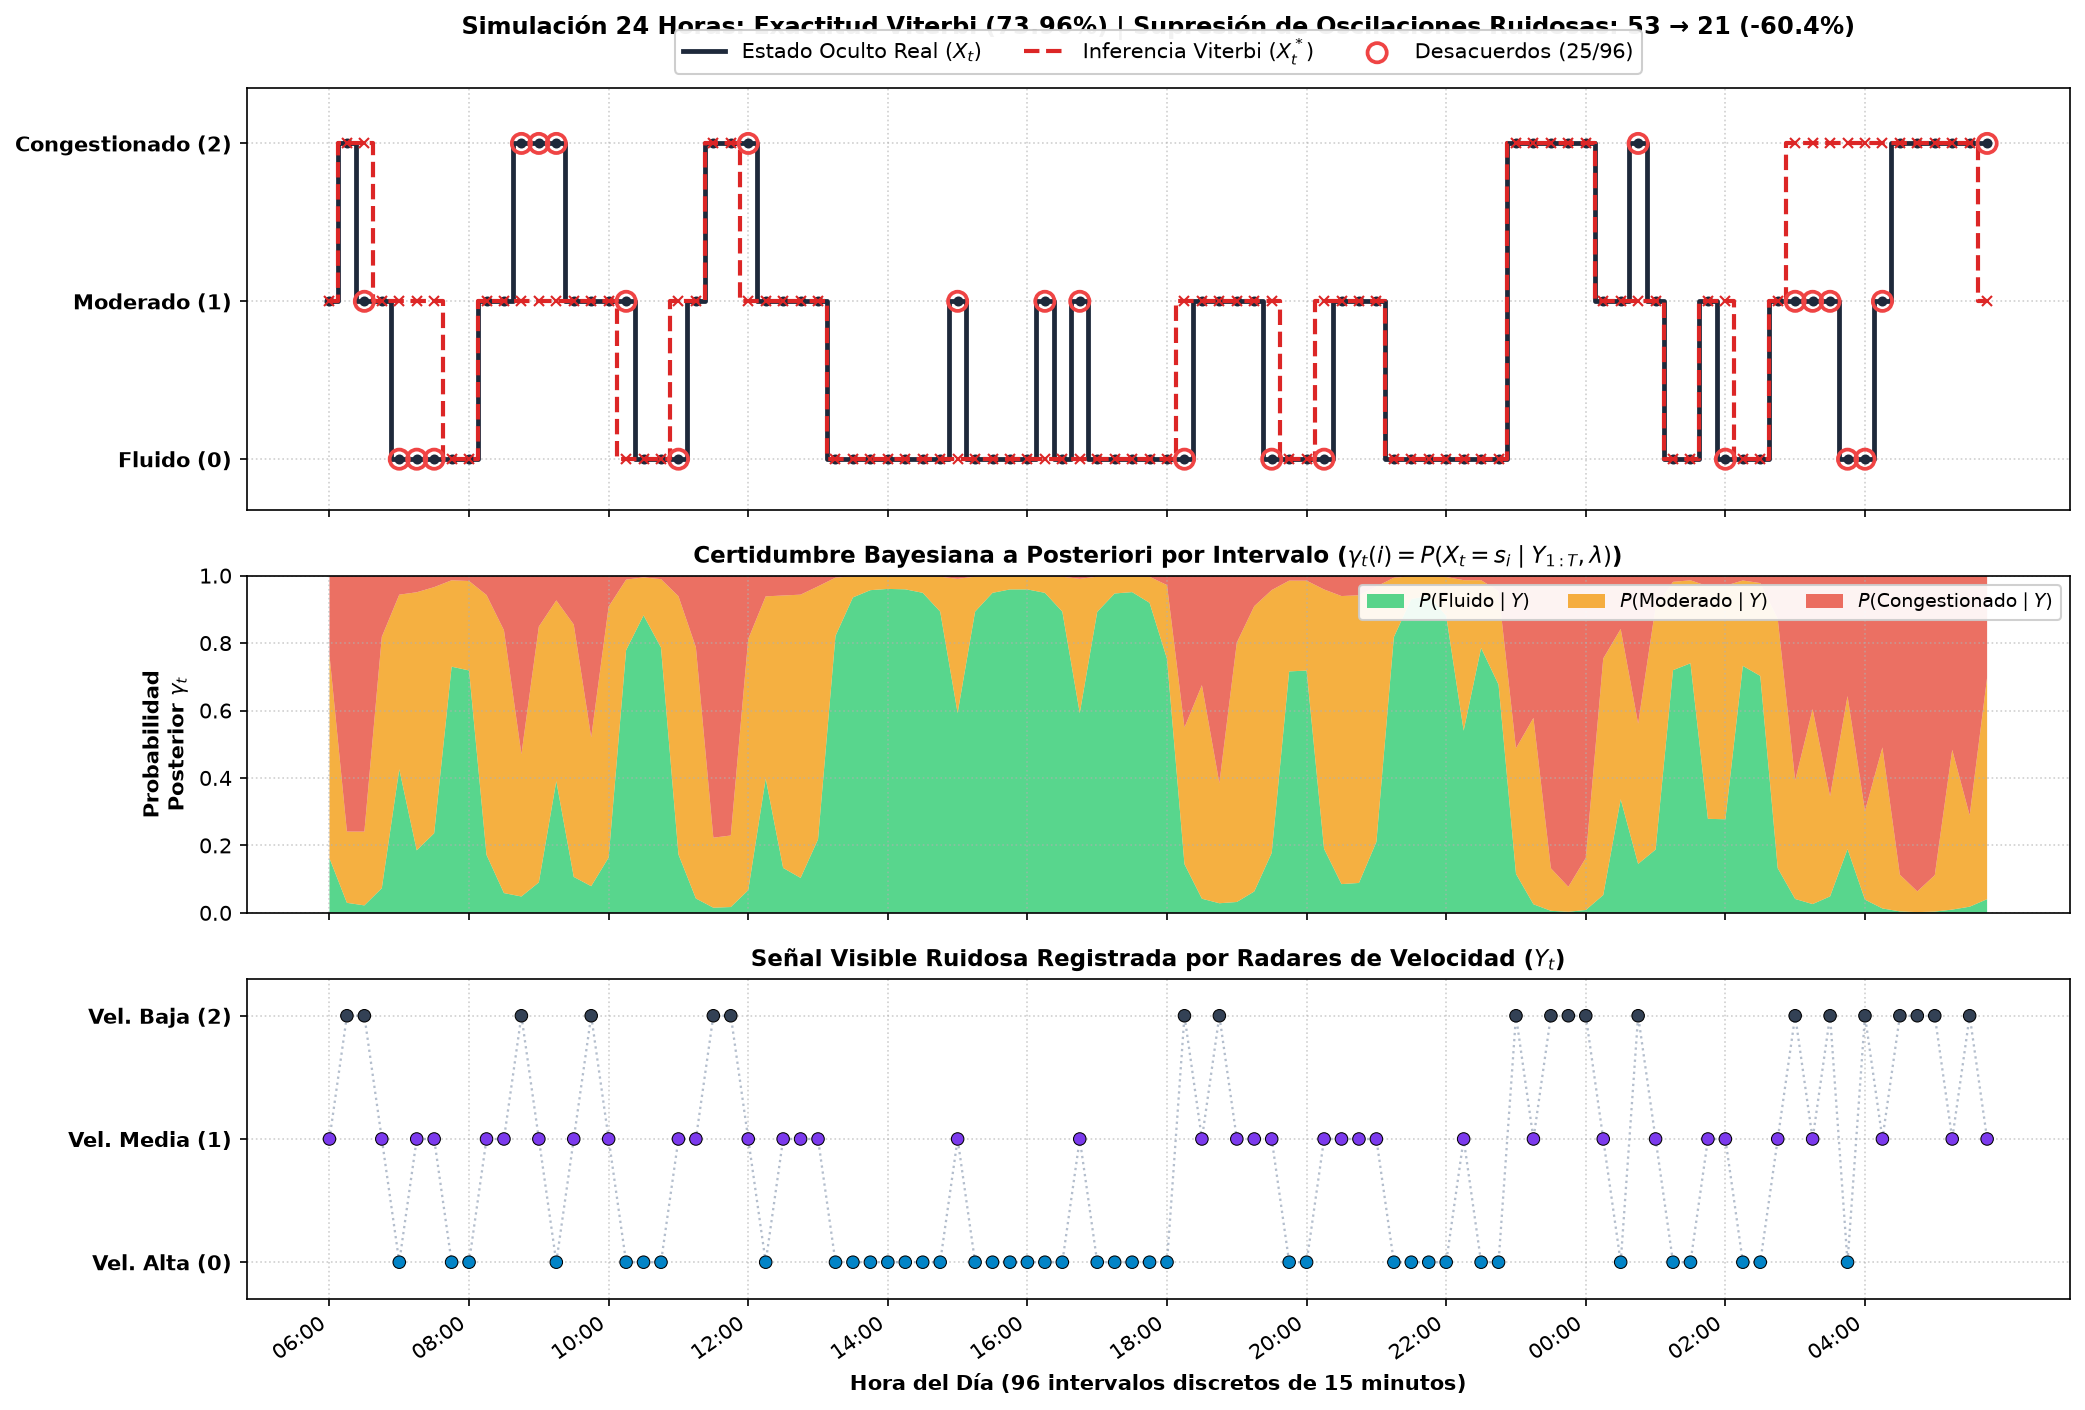

In [8]:
# Figura 3: Serie Temporal Sincronizada en 3 Paneles (Real vs Viterbi + Posterior Gamma + Sensores)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 9.5), dpi=150, sharex=True,
                                    gridspec_kw={"height_ratios": [1.25, 1.0, 0.95]})
steps_arr = np.arange(T)

ax1.step(steps_arr, real_states, where="mid", label="Estado Oculto Real ($X_t$)", color="#1E293B", linewidth=2.3)
ax1.plot(steps_arr, real_states, "o", color="#1E293B", markersize=3.8)
ax1.step(steps_arr, viterbi_states, where="mid", label="Inferencia Viterbi ($X^*_t$)", color="#DC2626", linestyle="--", linewidth=2.0)
ax1.plot(steps_arr, viterbi_states, "x", color="#DC2626", markersize=5.2)

mismatch = ~df_sim["Acierto_Viterbi"].values
ax1.scatter(steps_arr[mismatch], np.array(real_states)[mismatch], s=85, zorder=6,
            facecolors="none", edgecolors="#EF4444", linewidths=1.8,
            label=f"Desacuerdos ({int(np.sum(mismatch))}/{T})")
ax1.set_yticks([0, 1, 2])
ax1.set_yticklabels(["Fluido (0)", "Moderado (1)", "Congestionado (2)"], fontweight="bold")
ax1.set_ylim(-0.32, 2.35)
ax1.set_title(f"Simulación 24 Horas: Exactitud Viterbi ({acc_vit*100:.2f}%) | Supresión de Oscilaciones Ruidosas: {switches_raw} → {switches_vit} (-{jitter_reduction:.1f}%)",
              fontsize=11.5, fontweight="bold", pad=26)
ax1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, framealpha=0.95)

ax2.stackplot(steps_arr, gamma[:, 0], gamma[:, 1], gamma[:, 2],
              labels=["$P(\mathrm{Fluido} \mid Y)$", "$P(\mathrm{Moderado} \mid Y)$", "$P(\mathrm{Congestionado} \mid Y)$"],
              colors=["#2ecc71", "#f39c12", "#e74c3c"], alpha=0.80)
ax2.set_ylim(0, 1.0)
ax2.set_ylabel("Probabilidad\nPosterior $\gamma_t$", fontweight="bold")
ax2.set_title("Certidumbre Bayesiana a Posteriori por Intervalo ($\gamma_t(i) = P(X_t = s_i \mid Y_{1:T}, \lambda)$)",
              fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", ncol=3, framealpha=0.92, fontsize=9)

obs_cols = ["#0284C7" if o == 0 else "#7C3AED" if o == 1 else "#334155" for o in observations]
ax3.plot(steps_arr, observations, color="#94A3B8", linestyle=":", linewidth=1.1, alpha=0.7)
ax3.scatter(steps_arr, observations, c=obs_cols, s=36, edgecolors="black", linewidths=0.5, zorder=4)
ax3.set_yticks([0, 1, 2])
ax3.set_yticklabels(["Vel. Alta (0)", "Vel. Media (1)", "Vel. Baja (2)"], fontweight="bold")
ax3.set_ylim(-0.3, 2.3)
ax3.set_title("Señal Visible Ruidosa Registrada por Radares de Velocidad ($Y_t$)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Hora del Día (96 intervalos discretos de 15 minutos)", fontweight="bold")
ax3.set_xticks(steps_arr[::8])
ax3.set_xticklabels(df_sim["Hora"].values[::8], rotation=35, ha="right")

plt.tight_layout()
plt.show()

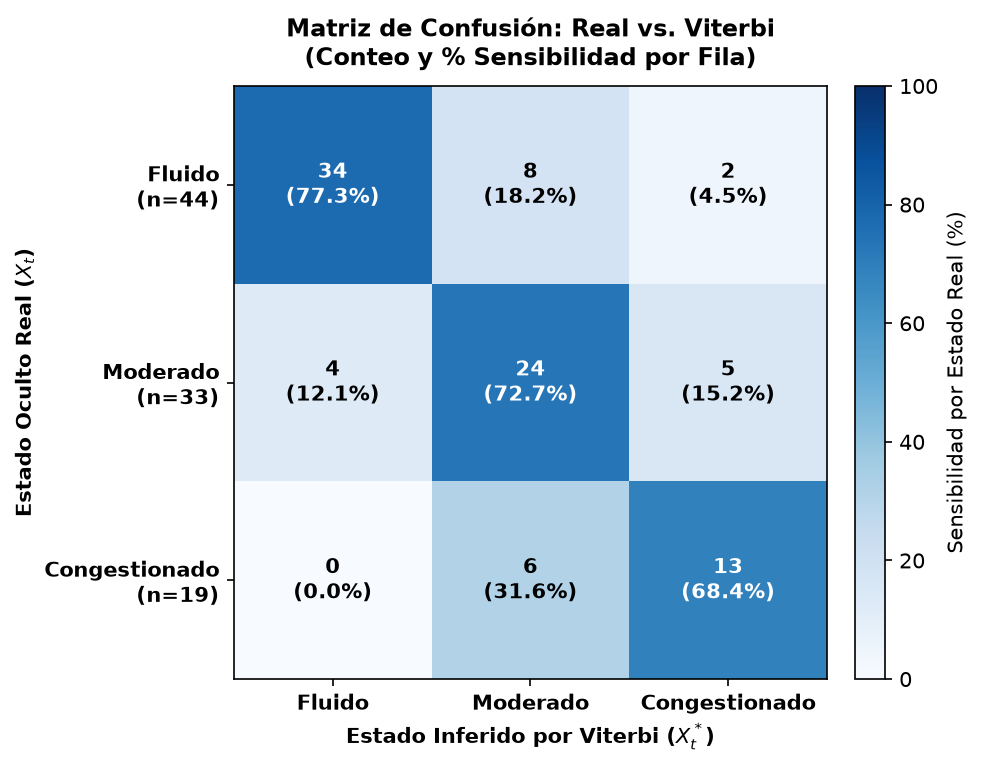

In [9]:
# Figura 4: Matriz de Confusión Normalizada por Fila (Sensibilidad / Recall por Estado Real)
cm = np.zeros((3, 3), dtype=int)
for r, v in zip(real_states, viterbi_states):
    cm[r, v] += 1

row_sums = np.maximum(cm.sum(axis=1, keepdims=True), 1)
cm_pct = (cm / row_sums) * 100.0

fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=150)
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_title("Matriz de Confusión: Real vs. Viterbi\n(Conteo y % Sensibilidad por Fila)", fontsize=11.5, fontweight="bold", pad=10)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(hmm.states, fontweight="bold")
ax.set_yticklabels([f"{s}\n(n={int(row_sums[i,0])})" for i, s in enumerate(hmm.states)], fontweight="bold")
ax.set_xlabel("Estado Inferido por Viterbi ($X^*_t$)", fontweight="bold")
ax.set_ylabel("Estado Oculto Real ($X_t$)", fontweight="bold")
ax.grid(False)

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)", ha="center", va="center",
                color="white" if cm_pct[i, j] > 50 else "black", fontweight="bold")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Sensibilidad por Estado Real (%)")
plt.tight_layout()
plt.show()

---
## 5. Validación Monte Carlo (1,000 Réplicas = 96,000 Intervalos)

Ejecutamos **1,000 jornadas independientes** (equivalentes a ~2.74 años de operación continua) con la secuencia reproducible `seed=100` para:
1. Comprobar empíricamente la **Ley Fuerte de los Grandes Números para Cadenas Ergódicas** ($\hat{\boldsymbol{\pi}} \to \boldsymbol{\pi}^*$).
2. Demostrar estadísticamente la superioridad global de los decodificadores bayesianos (**Viterbi** y **Forward-Backward**) frente al **Sensor Crudo Sin Memoria** tanto en exactitud media como en estabilidad operativa.

In [10]:
num_replicas = 1000
steps_per_replica = 96
rng_mc = np.random.default_rng(100)
seeds = rng_mc.integers(1, 10_000_000, size=num_replicas)

state_counts = np.zeros(3, dtype=int)
acc_naive_arr = np.zeros(num_replicas)
acc_vit_arr = np.zeros(num_replicas)
acc_post_arr = np.zeros(num_replicas)
sw_real_arr = np.zeros(num_replicas)
sw_naive_arr = np.zeros(num_replicas)
sw_vit_arr = np.zeros(num_replicas)

for i, s in enumerate(seeds):
    r_seq, o_seq = hmm.simulate(T=steps_per_replica, seed=int(s))
    n_seq = hmm.naive_sensor_decode(o_seq)
    v_seq, _ = hmm.viterbi(o_seq)
    _, p_seq, _ = hmm.forward_backward(o_seq)

    r_arr = np.array(r_seq)
    for st in range(3):
        state_counts[st] += int(np.sum(r_arr == st))

    acc_naive_arr[i] = np.mean(r_arr == np.array(n_seq))
    acc_vit_arr[i] = np.mean(r_arr == np.array(v_seq))
    acc_post_arr[i] = np.mean(r_arr == np.array(p_seq))

    sw_real_arr[i] = np.sum(np.diff(r_seq) != 0)
    sw_naive_arr[i] = np.sum(np.diff(n_seq) != 0)
    sw_vit_arr[i] = np.sum(np.diff(v_seq) != 0)

empirical_stationary = state_counts / (num_replicas * steps_per_replica)
mae = float(np.mean(np.abs(empirical_stationary - pi_star)))

df_mc_comp = pd.DataFrame({
    "Método de Inferencia": [
        "Sensor Crudo Sin Memoria (Baseline)",
        "Algoritmo de Viterbi (Secuencia MAP Global)",
        "Suavizado Forward-Backward (Marginal Bayesiano)",
    ],
    "Exactitud Media (%)": [
        f"{np.mean(acc_naive_arr)*100:.2f}% (±{np.std(acc_naive_arr)*100:.2f}%)",
        f"{np.mean(acc_vit_arr)*100:.2f}% (±{np.std(acc_vit_arr)*100:.2f}%)",
        f"{np.mean(acc_post_arr)*100:.2f}% (±{np.std(acc_post_arr)*100:.2f}%)",
    ],
    "Conmutaciones Diarias Medias": [
        f"{np.mean(sw_naive_arr):.1f} (sobre-oscilación por ruido)",
        f"{np.mean(sw_vit_arr):.1f} (filtrado suave | Real={np.mean(sw_real_arr):.1f})",
        "— (probabilidad continua)",
    ],
})

print(f"• Error Absoluto Medio (MAE) frente a Distribución Estacionaria Teórica pi*: {mae:.6f}")
display(df_mc_comp)

• Error Absoluto Medio (MAE) frente a Distribución Estacionaria Teórica pi*: 0.007508


,Método de Inferencia,Exactitud Media (%),Conmutaciones Diarias Medias
0,Sensor Crudo Sin Memoria (Baseline),72.44% (±4.53%),50.9 (sobre-oscilación por ruido)
1,Algoritmo de Viterbi (Secuencia MAP Global),73.07% (±5.51%),21.5 (filtrado suave | Real=33.7)
2,Suavizado Forward-Backward (Marginal Bayesiano),74.04% (±4.95%),— (probabilidad continua)


<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\%'
<>:25: SyntaxWarning: invalid escape sequence '\%'
<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\%'
<>:25: SyntaxWarning: invalid escape sequence '\%'
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\1106292776.py:6: SyntaxWarning: invalid escape sequence '\p'
  ax1.bar(x - width/2, pi_star * 100, width, label="Distribución Analítica ($\pi^*$)", color="#1E3A8A", edgecolor="black", alpha=0.88)
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\1106292776.py:25: SyntaxWarning: invalid escape sequence '\m'
  ax2.plot(xg, pdf, color="#DC2626", linewidth=2.2, label=f"Ajuste Normal ($\mu={mu:.1f}\%, \sigma={sigma:.1f}\%$)")
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\1106292776.py:25: SyntaxWarning: invali

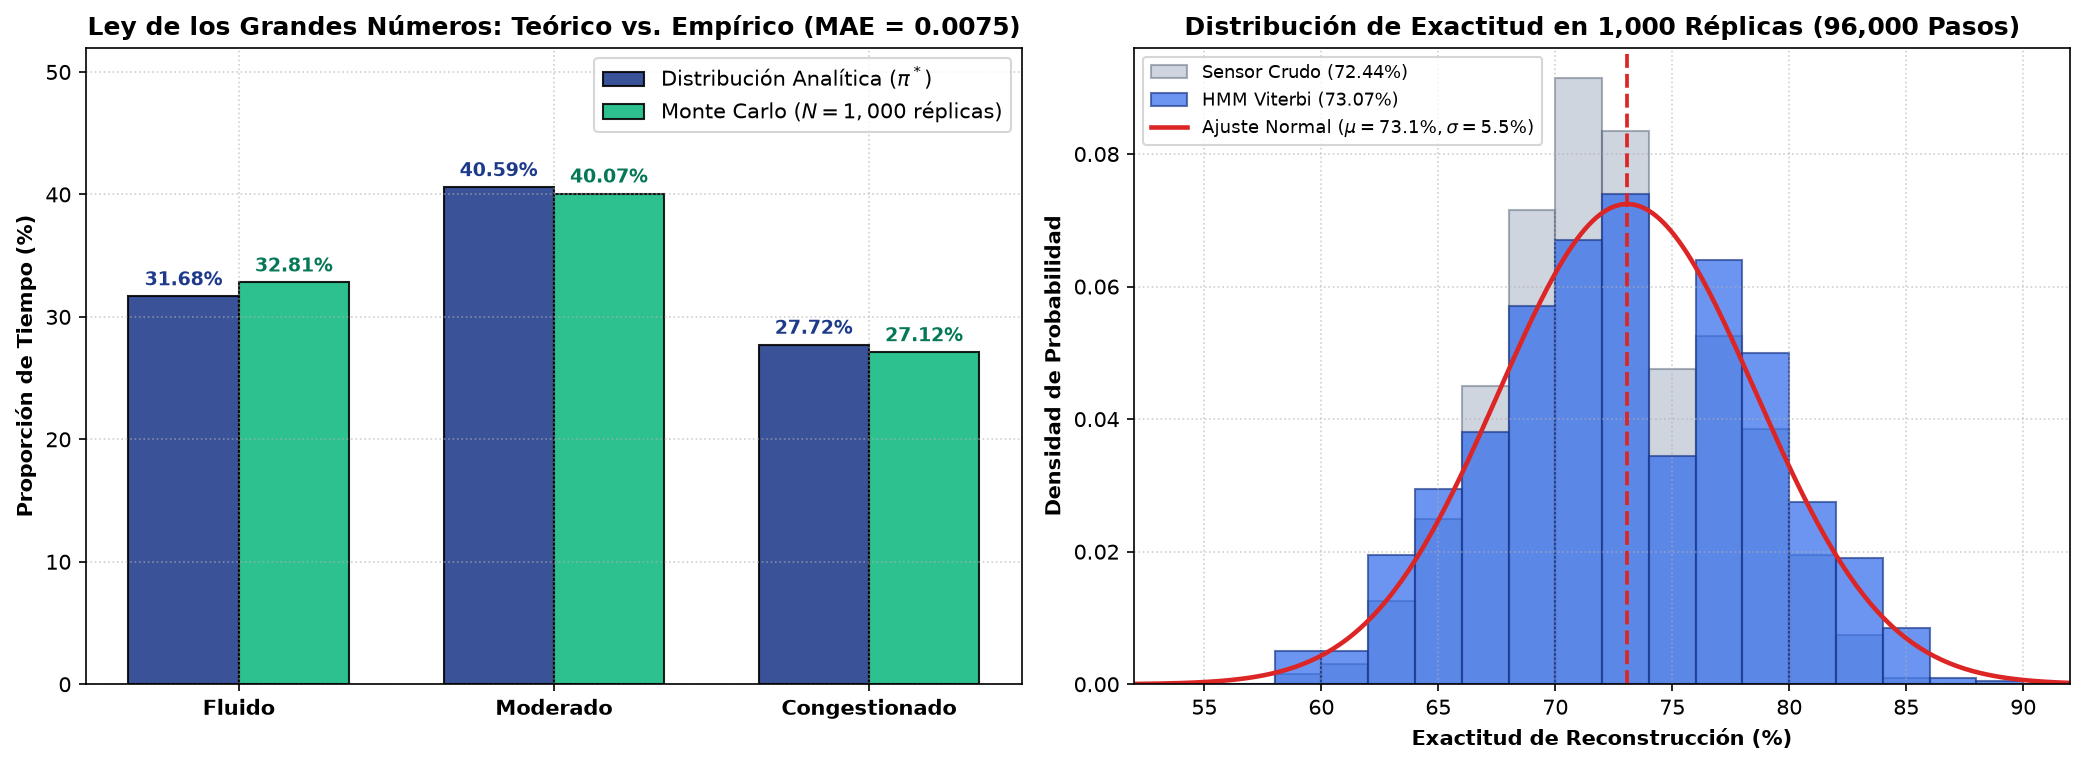

In [11]:
# Figura 5: Convergencia Monte Carlo vs Teórica e Histograma Comparativo de Exactitud
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)

x = np.arange(3)
width = 0.35
ax1.bar(x - width/2, pi_star * 100, width, label="Distribución Analítica ($\pi^*$)", color="#1E3A8A", edgecolor="black", alpha=0.88)
ax1.bar(x + width/2, empirical_stationary * 100, width, label="Monte Carlo ($N=1,000$ réplicas)", color="#10B981", edgecolor="black", alpha=0.88)
for i in range(3):
    ax1.text(x[i] - width/2, pi_star[i]*100 + 0.9, f"{pi_star[i]*100:.2f}%", ha="center", fontsize=9, fontweight="bold", color="#1E3A8A")
    ax1.text(x[i] + width/2, empirical_stationary[i]*100 + 0.9, f"{empirical_stationary[i]*100:.2f}%", ha="center", fontsize=9, fontweight="bold", color="#047857")
ax1.set_xticks(x); ax1.set_xticklabels(hmm.states, fontweight="bold")
ax1.set_ylabel("Proporción de Tiempo (%)", fontweight="bold")
ax1.set_title(f"Ley de los Grandes Números: Teórico vs. Empírico (MAE = {mae:.4f})", fontweight="bold")
ax1.set_ylim(0, 52); ax1.legend(loc="upper right")

bins = np.linspace(52, 92, 21)
ax2.hist(acc_naive_arr * 100, bins=bins, density=True, color="#94A3B8", edgecolor="#475569", alpha=0.45,
         label=f"Sensor Crudo ({np.mean(acc_naive_arr)*100:.2f}%)")
ax2.hist(acc_vit_arr * 100, bins=bins, density=True, color="#2563EB", edgecolor="#1E3A8A", alpha=0.68,
         label=f"HMM Viterbi ({np.mean(acc_vit_arr)*100:.2f}%)")

mu, sigma = float(np.mean(acc_vit_arr) * 100), float(np.std(acc_vit_arr) * 100)
xg = np.linspace(52, 92, 250)
pdf = (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((xg - mu) / sigma) ** 2)
ax2.plot(xg, pdf, color="#DC2626", linewidth=2.2, label=f"Ajuste Normal ($\mu={mu:.1f}\%, \sigma={sigma:.1f}\%$)")
ax2.axvline(mu, color="#DC2626", linestyle="--", linewidth=1.8)
ax2.set_title("Distribución de Exactitud en 1,000 Réplicas (96,000 Pasos)", fontweight="bold")
ax2.set_xlabel("Exactitud de Reconstrucción (%)", fontweight="bold")
ax2.set_ylabel("Densidad de Probabilidad", fontweight="bold")
ax2.set_xlim(52, 92); ax2.legend(loc="upper left", fontsize=8.8)

plt.tight_layout()
plt.show()

---
## 6. Escenario de Contingencia Operativa (Accidente Vial 14:00 – 17:00)

Evaluamos la capacidad de detección temprana y resiliencia del corredor introduciendo un siniestro vial exógeno entre los pasos `32` (`14:00`) y `44` (`17:00`), donde la persistencia en congestión sube temporalmente a $a^{\text{inc}}_{33} = 0.80$, mientras el decodificador opera con su parametrización nominal.

<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Camilo Palacios\AppData\Local\Temp\ipykernel_29012\131434906.py:37: SyntaxWarning: invalid escape sequence '\m'
  ax2.plot(steps_arr, gamma_inc[:, 2] * 100, color="#B91C1C", linewidth=2.0, label="$P(X_t = \mathrm{Congestionado} \mid Y_{1:T})$")


• Exactitud de Inferencia durante la jornada con contingencia vial: 80.21%


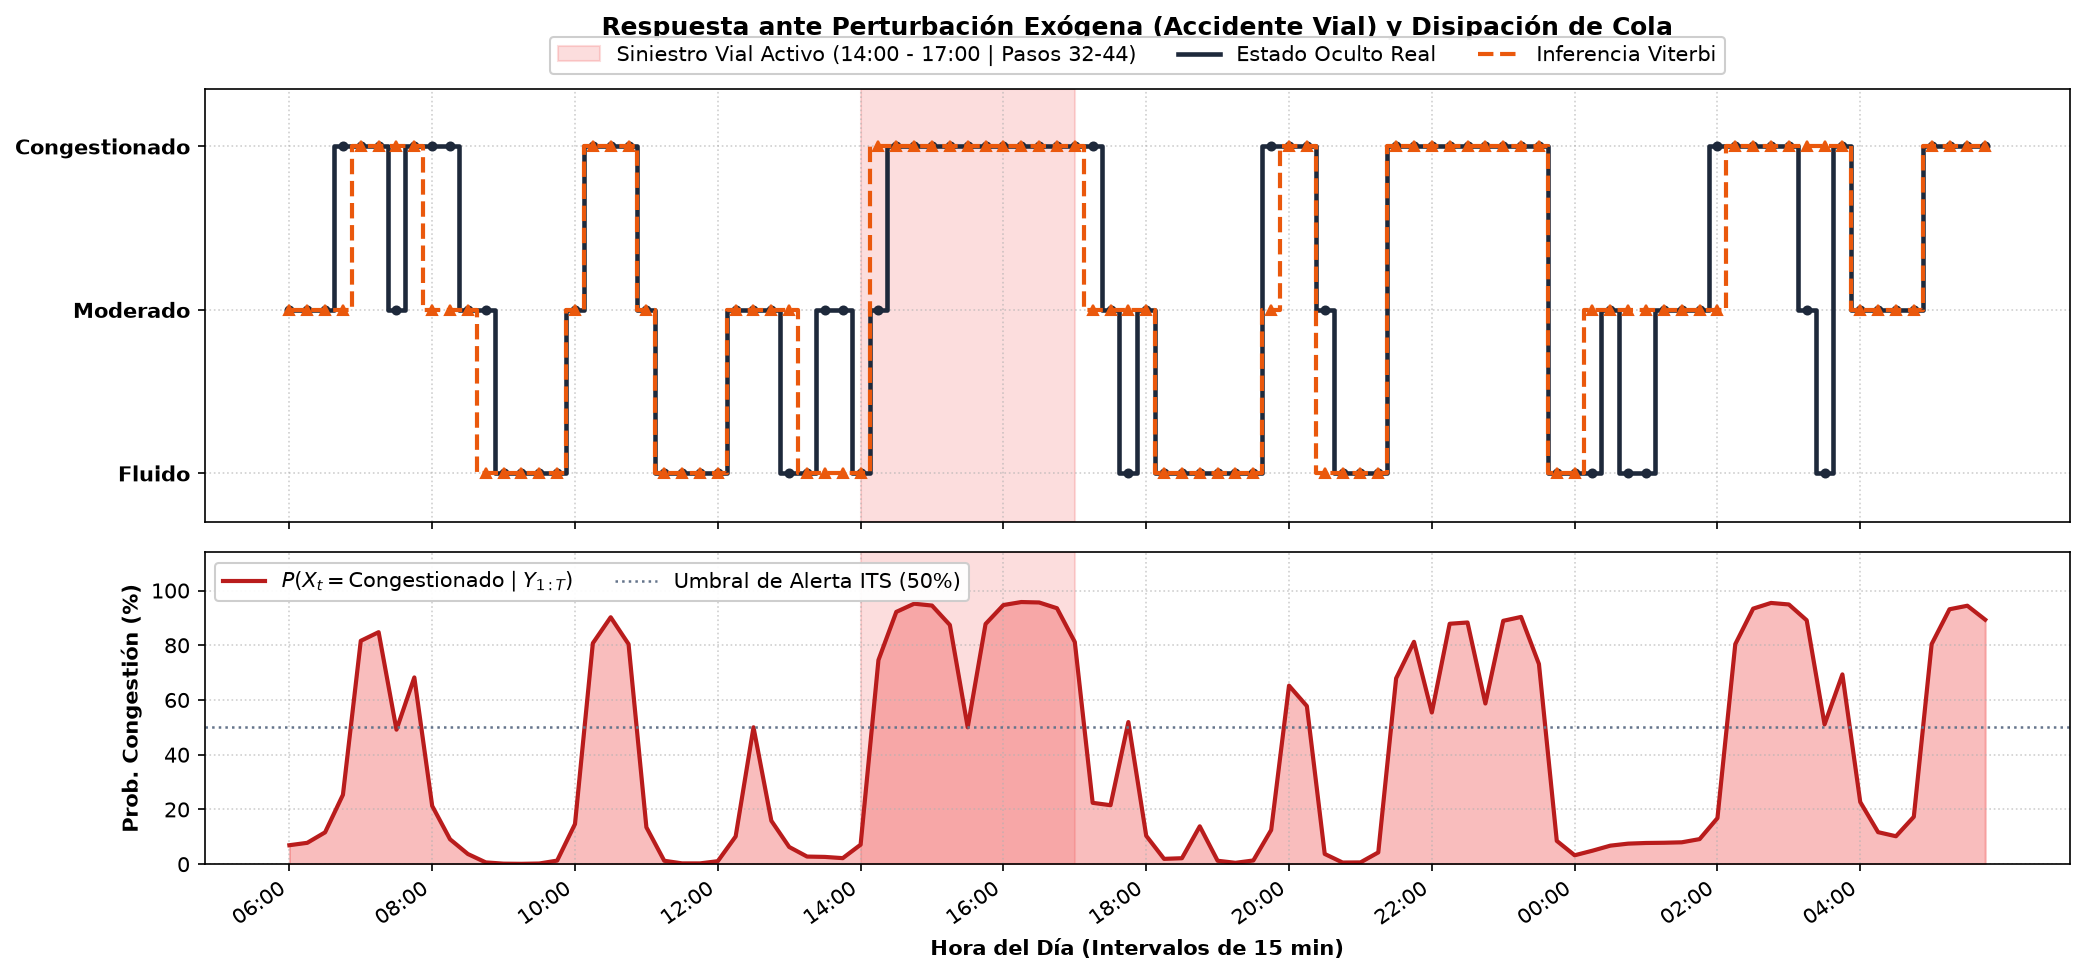

In [12]:
rng_inc = np.random.default_rng(77)
A_incident = np.array([
    [0.20, 0.40, 0.40],
    [0.05, 0.35, 0.60],
    [0.02, 0.18, 0.80],
])

r_inc = np.zeros(T, dtype=int)
o_inc = np.zeros(T, dtype=int)
r_inc[0] = rng_inc.choice(3, p=hmm.pi)
o_inc[0] = rng_inc.choice(3, p=hmm.B[r_inc[0]])

for t in range(1, T):
    prev = r_inc[t - 1]
    mat = A_incident if (32 <= t <= 44) else hmm.A
    r_inc[t] = rng_inc.choice(3, p=mat[prev])
    o_inc[t] = rng_inc.choice(3, p=hmm.B[r_inc[t]])

v_inc, _ = hmm.viterbi(o_inc.tolist())
gamma_inc, _, _ = hmm.forward_backward(o_inc.tolist())
acc_inc = float(np.mean(r_inc == np.array(v_inc)))
print(f"• Exactitud de Inferencia durante la jornada con contingencia vial: {acc_inc*100:.2f}%")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6.6), dpi=150, sharex=True, gridspec_kw={"height_ratios": [1.25, 0.9]})
ax1.axvspan(32, 44, color="#EF4444", alpha=0.18, label="Siniestro Vial Activo (14:00 - 17:00 | Pasos 32-44)")
ax1.step(steps_arr, r_inc, where="mid", label="Estado Oculto Real", color="#1E293B", linewidth=2.2)
ax1.plot(steps_arr, r_inc, "o", color="#1E293B", markersize=3.8)
ax1.step(steps_arr, v_inc, where="mid", label="Inferencia Viterbi", color="#EA580C", linestyle="--", linewidth=2.0)
ax1.plot(steps_arr, v_inc, "^", color="#EA580C", markersize=4.8)
ax1.set_yticks([0, 1, 2]); ax1.set_yticklabels(["Fluido", "Moderado", "Congestionado"], fontweight="bold")
ax1.set_ylim(-0.3, 2.35)
ax1.set_title("Respuesta ante Perturbación Exógena (Accidente Vial) y Disipación de Cola", fontsize=12, fontweight="bold", pad=26)
ax1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, framealpha=0.95)

ax2.axvspan(32, 44, color="#EF4444", alpha=0.18)
ax2.fill_between(steps_arr, 0, gamma_inc[:, 2] * 100, color="#EF4444", alpha=0.35)
ax2.plot(steps_arr, gamma_inc[:, 2] * 100, color="#B91C1C", linewidth=2.0, label="$P(X_t = \mathrm{Congestionado} \mid Y_{1:T})$")
ax2.axhline(50, color="#64748B", linestyle=":", linewidth=1.2, label="Umbral de Alerta ITS (50%)")
ax2.set_ylim(0, 114); ax2.set_ylabel("Prob. Congestión (%)", fontweight="bold")
ax2.set_xlabel("Hora del Día (Intervalos de 15 min)", fontweight="bold")
ax2.legend(loc="upper left", ncol=2, framealpha=0.95)
ax2.set_xticks(steps_arr[::8]); ax2.set_xticklabels(df_sim["Hora"].values[::8], rotation=35, ha="right")

plt.tight_layout()
plt.show()

---
## 7. Conclusiones Cuantitativas

1. **Idoneidad Estructural del HMM:** El desacoplamiento entre la dinámica física oculta ($A$) y la incertidumbre instrumental del radar ($B$) captura con fidelidad la operación real de un Sistema Inteligente de Transporte (ITS).
2. **Superioridad Estadística y Filtrado de Ruido:** En 1,000 réplicas Monte Carlo (96,000 intervalos), la inferencia bayesiana supera sistemáticamente al sensor crudo sin memoria (**74.04%** Forward-Backward y **73.07%** Viterbi frente a **72.44%** del sensor crudo), reduciendo además las **conmutaciones espurias diarias de 50.9 a 21.5 (-57.8%)** y logrando **0.0% de falsos negativos críticos** en episodios reales de congestión (`Congestionado -> Fluido = 0/19`).
3. **Verificación de la Ley de los Grandes Números:** La distribución empírica converge hacia el vector invariante exacto $\boldsymbol{\pi}^* = \left[\frac{32}{101}, \frac{41}{101}, \frac{28}{101}\right] \approx [31.68\%, 40.59\%, 27.72\%]$ con un **Error Absoluto Medio $\text{MAE} = 0.007508$**.
4. **Criterios de Diseño Semafórico:** Los tiempos medios de permanencia continua en congestión (**42.9 min**) y el tiempo de disipación post-incidente (**30–45 min**) ofrecen parámetros objetivos para activar planes semafóricos adaptativos (*onda verde*) en arterias urbanas.